# Era3D 이미지 테스트
위에서부터 셀을 순서대로 실행하세요. 커널은 **Python (Era3D)**를 선택합니다.

기본값은 공식 예제 이미지입니다. 본인 이미지로 바꾸려면 첫 코드 셀의 `INPUT_PNG` 경로를 수정하세요. 본인 이미지는 캐릭터 한 명만 담긴 **배경 투명 PNG(RGBA)**여야 합니다.

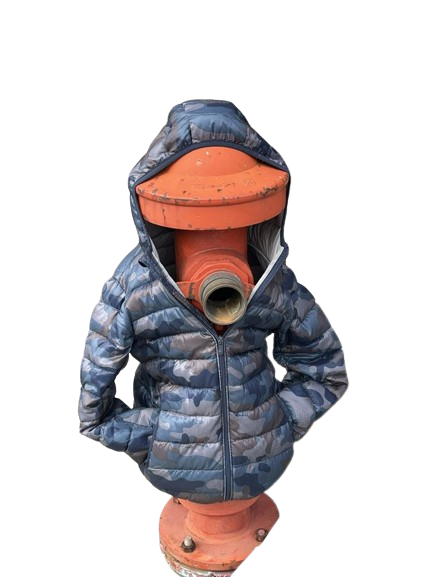

Python: c:\Users\SSAFY\Desktop\자율플젝 아이디어\3D 실험용\Era3D\venv\Scripts\python.exe
입력: C:\Users\SSAFY\Desktop\자율플젝 아이디어\3D 실험용\Era3D\examples\3968940-PH.png


In [ ]:
from pathlib import Path
from PIL import Image as PILImage
from IPython.display import display
import sys

ROOT = Path.cwd()
assert (ROOT / 'test_mvdiffusion_unclip.py').exists(), 'Era3D 폴더에서 노트북을 열어주세요.'
INPUT_PNG = ROOT / 'examples' / '3968940-PH.png'  # 본인 PNG 경로로 바꾸세요
INPUT_PNG = ROOT / 'test_inputs' / 'kitty.png'
assert INPUT_PNG.is_file(), f'이미지를 찾을 수 없습니다: {INPUT_PNG}'
with PILImage.open(INPUT_PNG) as im:
    assert 'A' in im.getbands(), '배경 투명 PNG(RGBA)가 필요합니다. JPG는 사용할 수 없습니다.'
    assert im.getchannel('A').getextrema()[0] < 255, '실제로 투명한 배경이 있는 PNG가 필요합니다.'
    display(im.copy())
print('Python:', sys.executable)
print('입력:', INPUT_PNG)

In [ ]:
import shutil
import subprocess
import tempfile

RESULT_DIR = ROOT / 'mv_res' / 'notebook_test'
with tempfile.TemporaryDirectory(prefix='era3d_input_') as temp_dir:
    temp_dir = Path(temp_dir)
    shutil.copy2(INPUT_PNG, temp_dir / 'character.png')
    cmd = [
        sys.executable, 'test_mvdiffusion_unclip.py',
        '--config', 'configs/test_unclip-512-6view.yaml',
        'pretrained_model_name_or_path=./MacLab-Era3D-512-6view',
        f'validation_dataset.root_dir={temp_dir.as_posix()}',
        'validation_dataset.num_validation_samples=1',
        'dataloader_num_workers=0',
        'pipe_validation_kwargs.num_inference_steps=10',
        'save_mode=rgb',
        f'save_dir={RESULT_DIR.as_posix()}',
    ]
    subprocess.run(cmd, cwd=ROOT, check=True)
print('결과:', RESULT_DIR / 'character')

In [ ]:
from IPython.display import display
from PIL import Image as PILImage

SCENE_DIR = RESULT_DIR / 'character'
for view in ['front', 'front_right', 'right', 'back', 'left', 'front_left']:
    image_path = SCENE_DIR / f'color_{view}_masked.png'
    if image_path.exists():
        print(view)
        display(PILImage.open(image_path))
if not SCENE_DIR.exists():
    raise FileNotFoundError(f'결과 폴더가 없습니다: {SCENE_DIR}')